# SAMI · Notebook 7 — Figures for the presentation: messages by category

**Mandate.** One figure, in Spanish and in English: how many messages each of the client's 10 categories has, plus
the "no topic" row, counted the way the dashboard's Category filter counts them. It writes
`docs/new_categories_es.png` and `docs/new_categories_en.png` (`docs/` is gitignored: the images are for the
presentation, not for the repo). Modules compute, this notebook consumes.

> **Rules.**
>
> 1. **Counts only.** No message text is read, shown or saved.
> 2. **Same counting as the dashboard.** Each message counts under its *author's* main category
>    (`fact_message[category_id]`), so the figures match `dim_category[n_messages]` and what the Category filter
>    shows. They are not the per-message labels (`message_category`), which give smaller numbers for the big topics.
> 3. **One data folder, named in the first cell** (`EXPORTS`, the committed `exports/`).

In [1]:
import sys, pathlib
# Locate the repo root by walking up from the working directory, so the notebook runs from notebooks/ or from the root.
_cwd = pathlib.Path.cwd()
ROOT = next((p for p in (_cwd, *_cwd.parents) if (p / "src" / "sami").is_dir()), None)
if ROOT is None:
    raise RuntimeError(f"Could not find src/sami/ above {_cwd}. Run this notebook from inside the repository.")
import warnings
warnings.filterwarnings("ignore")
import pandas as pd, matplotlib.pyplot as plt

EXPORTS = ROOT / "exports"
OUT = ROOT / "docs"                                # gitignored
DPI = 160                                          # 300 for a full-slide image
TEAL, GREY_BAR, INK, GREY = "#009ba4", "#c9c9c9", "#222222", "#666666"
print("data folder:", EXPORTS.relative_to(ROOT))

data folder: exports


## 1 · The counts

Messages per category under the author's main category. The check against `dim_category[n_messages]` fails loudly if the
two ever disagree. The "no topic" row (`category_id = -1`) holds the messages of users with no message of their own topic
(no text, or only "Ninguna").

In [2]:
dc = pd.read_csv(EXPORTS / "dim_category.csv")
fm = pd.read_csv(EXPORTS / "fact_message.csv", usecols=["category_id"])
meta = pd.read_csv(EXPORTS / "meta_run.csv").set_index("key")["value"]

counts = fm["category_id"].value_counts()
real = dc[dc["is_real_category"]]
assert (real.set_index("category_id")["n_messages"].astype(int) == counts.reindex(real["category_id"]).values).all(), \
    "fact_message counts differ from dim_category[n_messages]"

t = dc.assign(n=dc["category_id"].map(counts).fillna(0).astype(int))
t = t.sort_values(["is_real_category", "n"], ascending=[False, False])
assert t["n"].sum() == len(fm)
t["pct"] = t["n"] / len(fm) * 100
print(f"{len(fm):,} messages · {meta['ts_min'][:10]} to {meta['ts_max'][:10]}")
t[["name", "n", "pct"]].round(1)

6,373 messages · 2026-03-25 to 2026-10-23


,name,n,pct
0,Acceso a documentos y regularización,2782,43.7
1,Asistencia Humanitaria,1481,23.2
2,Acceso a servicios del Estado,569,8.9
3,Empleabilidad,342,5.4
4,Acceso a la protección internacional y asilo,333,5.2
5,Emprendimiento,250,3.9
6,Acceso a la nacionalidad,178,2.8
7,Entidades del Estado,168,2.6
9,Riesgos de protección,113,1.8
8,Recomendaciones para un viaje seguro,111,1.7


## 2 · The figure, in Spanish and in English

The category names are the client's (Spanish); long ones are shortened. The English names (`EN`) are our own
translations for the presentation, not MMC's: the client has no official English names. Check them with the client
before they go on a slide that will be shared.

saved docs/new_categories_es.png


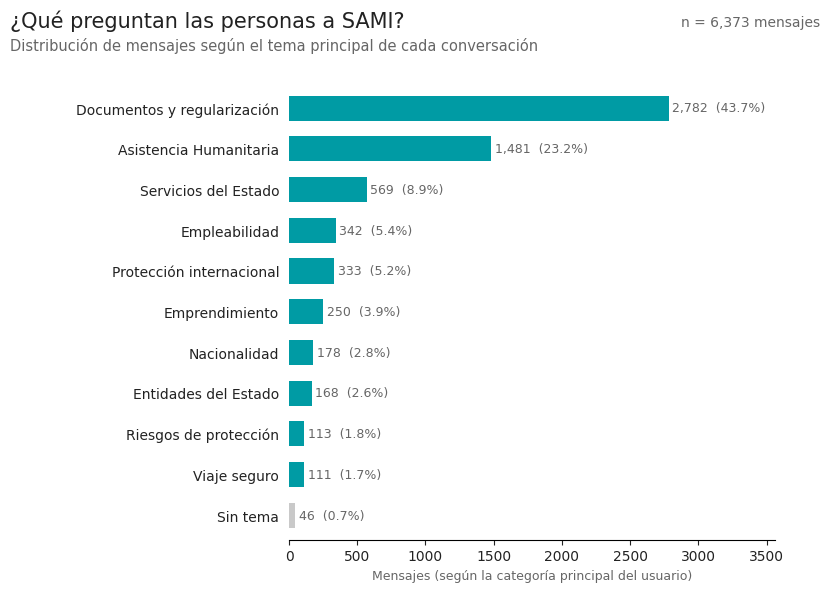

saved docs/new_categories_en.png


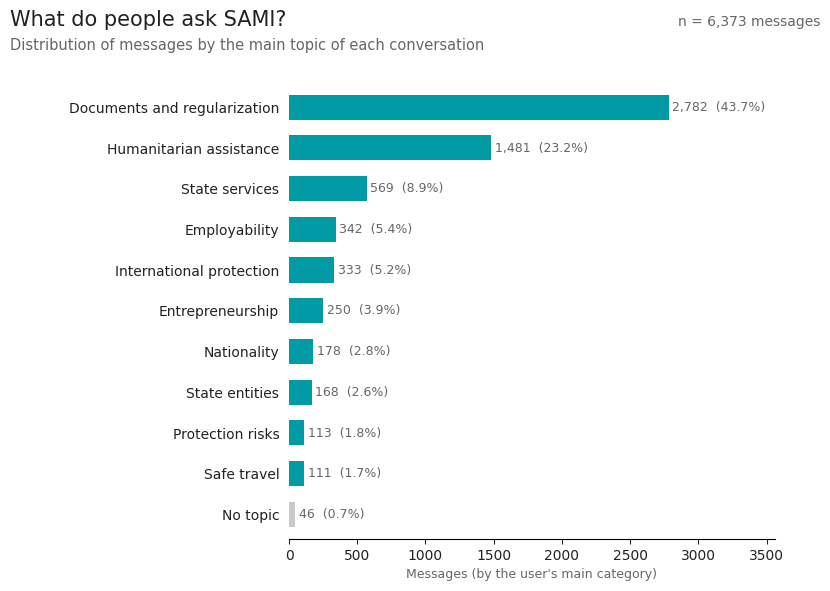

In [3]:
SHORT = {"Acceso a documentos y regularización": "Documentos y regularización",
         "Acceso a servicios del Estado": "Servicios del Estado",
         "Acceso a la protección internacional y asilo": "Protección internacional",
         "Acceso a la nacionalidad": "Nacionalidad",
         "Recomendaciones para un viaje seguro": "Viaje seguro"}
EN = {"Acceso a documentos y regularización": "Documents and regularization",
      "Asistencia Humanitaria": "Humanitarian assistance",
      "Acceso a servicios del Estado": "State services",
      "Empleabilidad": "Employability",
      "Acceso a la protección internacional y asilo": "International protection",
      "Emprendimiento": "Entrepreneurship",
      "Acceso a la nacionalidad": "Nationality",
      "Entidades del Estado": "State entities",
      "Riesgos de protección": "Protection risks",
      "Recomendaciones para un viaje seguro": "Safe travel"}
N = len(fm)
LANG = {"es": dict(title="¿Qué preguntan las personas a SAMI?",
                   subtitle="Distribución de mensajes según el tema principal de cada conversación", sub=f"n = {N:,} mensajes",
                   xlabel="Mensajes (según la categoría principal del usuario)", none="Sin tema"),
        "en": dict(title="What do people ask SAMI?",
                   subtitle="Distribution of messages by the main topic of each conversation", sub=f"n = {N:,} messages",
                   xlabel="Messages (by the user's main category)", none="No topic")}

def draw(lang):
    c = LANG[lang]
    d = t.iloc[::-1]
    label = (lambda n: EN[n]) if lang == "en" else (lambda n: SHORT.get(n, n))
    names = [c["none"] if cid == -1 else label(n) for cid, n in zip(d["category_id"], d["name"])]
    fig = plt.figure(figsize=(9, 6), facecolor="white")
    fig.text(0.05, 0.955, c["title"], fontsize=15, color=INK)
    fig.text(0.05, 0.915, c["subtitle"], fontsize=10.5, color=GREY)
    fig.text(0.95, 0.955, c["sub"], fontsize=10, color=GREY, ha="right")
    ax = fig.add_axes([0.36, 0.10, 0.54, 0.76])
    ax.barh(names, d["n"], color=[GREY_BAR if cid == -1 else TEAL for cid in d["category_id"]], height=.62)
    for y_, (v, p) in enumerate(zip(d["n"], d["pct"])):
        ax.text(v + 25, y_, f"{v:,}  ({p:.1f}%)", va="center", fontsize=9, color=GREY)
    ax.set_xlim(0, d["n"].max() * 1.28); ax.set_ylim(-0.6, len(names) - 0.4)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(left=False, labelsize=10, colors=INK)
    ax.set_xlabel(c["xlabel"], color=GREY, fontsize=9)
    return fig

OUT.mkdir(exist_ok=True)
for lang in ("es", "en"):
    fig = draw(lang)
    path = OUT / f"new_categories_{lang}.png"
    fig.savefig(path, dpi=DPI, facecolor="white")
    print("saved", path.relative_to(ROOT))
    plt.show()